# 1 - modele Markov ascunse

stari: camerele 1 2 3 4

obs: red green blue blue red

In [1]:
import numpy as np
pi = np.array([0.25, 0.25, 0.25, 0.25])

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

O = [0, 1, 2, 2, 0]

print("pi =", pi)
print("B =")
print(B)
print("O =", O)

pi = [0.25 0.25 0.25 0.25]
B =
[[0.7 0.2 0.1]
 [0.2 0.6 0.2]
 [0.1 0.3 0.6]
 [0.5 0.2 0.3]]
O = [0, 1, 2, 2, 0]


## Algoritmul Viterbi

init:

delta_1(j) = pi_j * b_j(o_1)

recurenta:

delta_t(j) = b_j(o_t) * max_i(delta_(t-1)(i) * a_ij)

predecesori:

psi_t(j) = argmax_i(delta_(t-1)(i) * a_ij)

la final reconstruim traseul prin backtracking

In [3]:
def viterbi(A, pi, B, O):
    T = len(O)
    n = len(pi)

    delta = np.zeros((T, n))
    psi = np.zeros((T, n), dtype=int)

    # init
    delta[0] = pi * B[:, O[0]]

    # recurenta
    for t in range(1, T):
        for j in range(n):
            v = delta[t-1] * A[:, j]

            psi[t, j] = np.argmax(v)
            delta[t, j] = B[j, O[t]] * np.max(v)

    # bkt
    traseu = [np.argmax(delta[T-1])]

    for t in range(T-1, 0, -1):
        traseu.insert(0, psi[t, traseu[0]])

    probabilitate = np.max(delta[T-1])

    return delta, psi, traseu, probabilitate

## a) robotul poate ramane pe loc

prob de stationare este 0.2

prob deplasarii la fiecare vecin este 0.4

In [4]:
A1 = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2]
])

delta1, psi1, traseu1, p1 = viterbi(A1, pi, B, O)

print("matricea delta:")
print(delta1)

print("\npredecesorii psi:")
print(psi1 + 1)

print("\ntraseul optim:")
print(np.array(traseu1) + 1)

print("\nprob. comuna:")
print(p1)

matricea delta:
[[1.75000e-01 5.00000e-02 2.50000e-02 1.25000e-01]
 [1.00000e-02 4.20000e-02 1.50000e-02 1.40000e-02]
 [1.68000e-03 1.68000e-03 1.00800e-02 1.80000e-03]
 [7.20000e-05 8.06400e-04 1.20960e-03 1.20960e-03]
 [3.38688e-04 9.67680e-05 4.83840e-05 2.41920e-04]]

predecesorii psi:
[[1 1 1 1]
 [4 1 4 1]
 [2 2 2 3]
 [4 3 3 3]
 [4 3 4 3]]

traseul optim:
[1 2 3 4 1]

prob. comuna:
0.00033868799999999997


##  b) - robotul nu mai poate ramane pe loc

prob fiecarei deplasari este 0.5

In [9]:
A2 = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0]
])

delta2, psi2, traseu2, p2 = viterbi(A2, pi, B, O)

print("matricea delta:")
print(delta2)

print("\npredecesorii psi:")
print(psi2 + 1)

print("\ntraseul optim:")
print(np.array(traseu2) + 1)

print("\nprob. comuna:")
print(p2)

matricea delta:
[[1.750000e-01 5.000000e-02 2.500000e-02 1.250000e-01]
 [1.250000e-02 5.250000e-02 1.875000e-02 1.750000e-02]
 [2.625000e-03 1.875000e-03 1.575000e-02 2.812500e-03]
 [1.406250e-04 1.575000e-03 8.437500e-04 2.362500e-03]
 [8.268750e-04 8.437500e-05 1.181250e-04 2.109375e-04]]

predecesorii psi:
[[1 1 1 1]
 [4 1 4 1]
 [2 3 2 3]
 [4 3 4 3]
 [4 3 4 3]]

traseul optim:
[1 2 3 4 1]

prob. comuna:
0.0008268749999999999


## comparatia rezultatelor:
traseul optim este acelasi in ambele cazuri

prob omuna este mai mare in cazul b deoarece probabilitatea deplasarii creste de la 0.4 la 0.5


In [6]:
print("cazul a:", p1)
print("cazul b:", p2)

print("traseu a:", np.array(traseu1) + 1)
print("traseu b:", np.array(traseu2) + 1)

cazul a: 0.00033868799999999997
cazul b: 0.0008268749999999999
traseu a: [1 2 3 4 1]
traseu b: [1 2 3 4 1]


## 2.a - Retele Markov

reprezentam graful si calculam probabilitatea conditionata

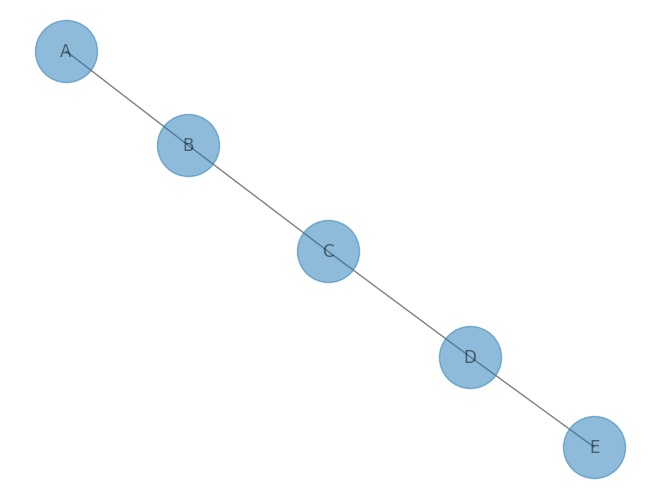

In [13]:
import networkx as nx
import matplotlib.pyplot as plt

G1 = nx.Graph()
G1.add_edges_from([
    ('A','B'), ('B','C'), ('C','D'), ('D','E')
])

pos1 = nx.spring_layout(G1, seed=1)

nx.draw(G1, with_labels=True, pos=pos1,
        alpha=0.5, node_size=2000)

plt.savefig("graf_2a.png")
plt.show()

## 2. b)

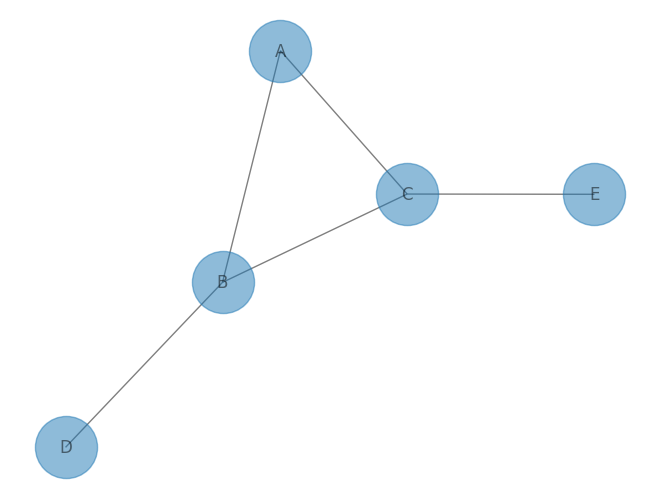

In [12]:
G2 = nx.Graph()
G2.add_edges_from([
    ('A','B'), ('A','C'), ('B','C'),
    ('B','D'), ('C','E')
])

pos2 = nx.spring_layout(G2, seed=1)

nx.draw(G2, with_labels=True, pos=pos2,
        alpha=0.5, node_size=2000)

plt.savefig("graf_2b.png")
plt.show()

##  3 - inferenta bayesiana

model beta-binomial. folosim distributia beta a priori si actualizam parametrii cu datele observate.

### 3.a) primul lot

In [14]:
from scipy.stats import beta as beta_dist

# date initiale
alpha = 2
beta = 8
N = 20
y = 5

# distributia a posteriori
alpha_post = alpha + y
beta_post = beta + N - y

media = alpha_post / (alpha_post + beta_post)

print("posterior:", alpha_post, beta_post)
print("distributia:", f"Beta({alpha_post}, {beta_post})")
print("media:", media)

posterior: 7 23
distributia: Beta(7, 23)
media: 0.23333333333333334


### graficul distributiilor a priori si a posteriori

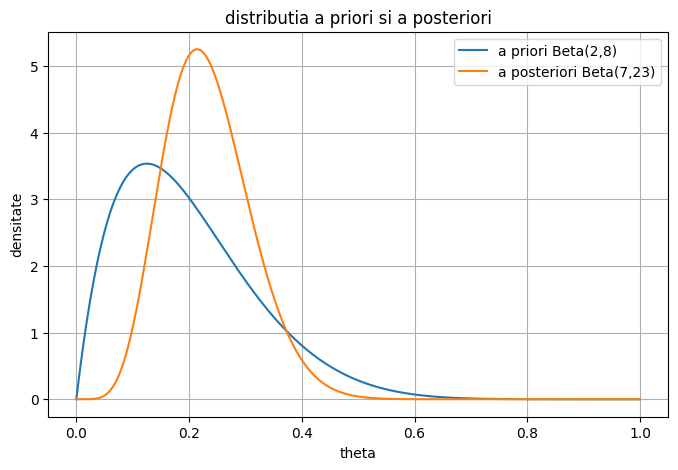

In [15]:
x = np.linspace(0, 1, 500)

prior = beta_dist.pdf(x, 2, 8)
posterior = beta_dist.pdf(x, 7, 23)

plt.figure(figsize=(8, 5))

plt.plot(x, prior, label="a priori Beta(2,8)")
plt.plot(x, posterior, label="a posteriori Beta(7,23)")

plt.xlabel("theta")
plt.ylabel("densitate")
plt.title("distributia a priori si a posteriori")
plt.legend()
plt.grid()

plt.savefig("grafic_3a.png")
plt.show()

### 3.b) ambele loturi

In [16]:
# datele celor doua loturi
N1, y1 = 20, 5
N2, y2 = 15, 3

# combinam datele
N = N1 + N2
y = y1 + y2

# posterior
alpha_b = 2 + y
beta_b = 8 + N - y

media_b = alpha_b / (alpha_b + beta_b)

print("N =", N)
print("y =", y)
print("posterior: Beta(", alpha_b, ",", beta_b, ")")
print("media:", media_b)

N = 35
y = 8
posterior: Beta( 10 , 35 )
media: 0.2222222222222222


### 3.c) doar al doilea lot

In [18]:
# folosim doar al doilea lot
N = 15
y = 3

# pastram priorul beta(2,8)
alpha_c = 2 + y
beta_c = 8+ N - y

media_c = alpha_c / (alpha_c + beta_c)

print("posterior : Beta(", alpha_c, "," , beta_c, ")" )
print("media : ", media_c)

posterior : Beta( 5 , 20 )
media :  0.2


### comparatia rezultatelor
la b folosim ambele loturi iar la c folosim doar al doilea lot.

primul lot are o proportie mai mare de produse defecte si modifica media posteriorului